# Vision and Browser Agents — Colab adaptation

Source: [Hugging Face Agents Course — vision_web_browser.py](https://huggingface.co/agents-course/notebooks/blob/main/unit2/smolagents/vision_web_browser.py). This notebook reconstructs the public browser exercise rather than reproducing the complete original script. The original file is a Python script for local execution, not a Colab notebook. This adaptation uses a headless Playwright Chromium browser, Qwen visual input, native tool calls, and real screenshots captured by a browser tool. No logins or private pages are needed. The task is to help Alfred research Wonder Woman’s visual appearance from public images and Wikipedia.


> **Validation status.** Preserved outputs are historical evidence from the supplied notebook. Local checks may add their own evidence. Consult the accompanying validation report for the checks run on this revision and the exercises still pending authenticated Colab verification.

In [2]:
%pip install -q "smolagents[openai,toolkit]==1.26.0" "requests==2.32.4" playwright ddgs pillow beautifulsoup4


## Configure Groq and browser access

Enable the existing `GROQ_API_KEY`. The visual exercise uses a model with image input.
Playwright installs its matching Chromium headless shell when needed. The notebook opens
only the public course page and needs network access for Chromium and the article.


In [ ]:
import os
from time import monotonic, sleep
from uuid import uuid4

from openai import APIConnectionError, APIStatusError, OpenAI, RateLimitError
from smolagents import OpenAIModel, ToolCallingAgent
from smolagents.models import ChatMessageToolCall, ChatMessageToolCallFunction

def read_secret(name):
    value = os.getenv(name)
    if value:
        return value
    try:
        from google.colab import userdata
    except ImportError:
        return None
    try:
        return userdata.get(name)
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        return None

GROQ_API_KEY = read_secret("GROQ_API_KEY")
GROQ_BASE = "https://api.groq.com/openai/v1"
client = (OpenAI(api_key=GROQ_API_KEY, base_url=GROQ_BASE, timeout=20, max_retries=0)
          if GROQ_API_KEY else None)
MODEL_ID = os.getenv("GROQ_MODEL_ID", "qwen/qwen3.8-27b")
VISION_MODEL_ID = os.getenv("GROQ_VISION_MODEL_ID", "qwen/qwen3.8-27b")
TEXT_MODELS = (MODEL_ID, "openai/gpt-oss-20b", "qwen/qwen3.8-27b")
MODEL_REQUEST_LIMIT = int(os.getenv("GROQ_MAX_REQUESTS", "12"))
model_requests = 0
last_model_request = 0.0

class GroqAgentModel(OpenAIModel):
    """Use Groq's native tool validation and accept genuine text final answers."""
    def _prepare_completion_kwargs(self, *args, **kwargs):
        policy = getattr(self, "tool_policy", None)
        forced = policy() if policy and kwargs.get("tools_to_call_from") else None
        kwargs["tool_choice"] = (
            {"type": "function", "function": {"name": forced}} if forced else "auto"
        )
        request = super()._prepare_completion_kwargs(*args, **kwargs)
        request.pop("stop", None)
        for message in request["messages"]:
            message.pop("name", None)
        if request.get("tools"):
            request["parallel_tool_calls"] = False
        # Keep tool calls and their observations together; do not truncate message history.
        request.setdefault("max_completion_tokens", 2000)
        return request

    def generate(self, messages, *args, tools_to_call_from=None, **kwargs):
        global model_requests, last_model_request
        original_model = self.model_id
        original_options = self.kwargs.copy()
        options = (original_model,) if original_model == VISION_MODEL_ID else TEXT_MODELS
        deadline = monotonic() + 150
        try:
            for attempt in range(2):
                if model_requests >= MODEL_REQUEST_LIMIT or monotonic() >= deadline:
                    raise RuntimeError("Model request budget exhausted.")
                self.model_id = options[min(attempt, len(options) - 1)]
                self.kwargs.pop("reasoning_effort", None)
                if self.model_id.startswith("openai/gpt-oss"):
                    self.kwargs["reasoning_effort"] = "low"
                elif self.model_id == VISION_MODEL_ID:
                    self.kwargs["reasoning_effort"] = "none"
                sleep(max(0, 30 - (monotonic() - last_model_request)))
                last_model_request = monotonic()
                model_requests += 1
                try:
                    reply = super().generate(
                        messages, *args, tools_to_call_from=tools_to_call_from, **kwargs
                    )
                except (APIStatusError, APIConnectionError) as exc:
                    status = getattr(exc, "status_code", 0) or 0
                    code = getattr(exc, "code", None)
                    recoverable = (status in (404, 429) or status >= 500 or status == 0
                                   or code in ("tool_use_failed", "model_decommissioned"))
                    if attempt or not recoverable:
                        raise RuntimeError(
                            f"Groq request failed for {self.model_id} (HTTP {status or 'connection'}, "
                            f"{code or type(exc).__name__})."
                        ) from None
                    if isinstance(exc, RateLimitError):
                        try:
                            delay = float(exc.response.headers.get("retry-after", "2"))
                        except ValueError:
                            delay = 2
                        if delay > 60:
                            raise RuntimeError(
                                f"Groq vision quota is limited; retry after {delay:g} seconds."
                            ) from None
                        sleep(max(1, min(delay, 60)))
                    print("Groq request interrupted; making one bounded retry.")
                    continue
                names = {tool.name for tool in tools_to_call_from or ()}
                text = reply.content
                if ("final_answer" in names and not reply.tool_calls
                        and isinstance(text, str) and text.strip()):
                    # smolagents expects a final_answer action. Carry the real text into
                    # that action locally without changing any external tool observations.
                    # Normalize only an explicit final-answer envelope, never arbitrary tool calls.
                    import json
                    try:
                        envelope = json.loads(text.strip())
                        if isinstance(envelope, dict) and envelope.get("name") == "final_answer":
                            answer = envelope.get("arguments", {}).get("answer")
                            if isinstance(answer, str):
                                text = answer
                    except (ValueError, TypeError):
                        pass
                    reply.tool_calls = [ChatMessageToolCall(
                        function=ChatMessageToolCallFunction(
                            name="final_answer", arguments={"answer": text.strip()}),
                        id=f"local_final_{uuid4().hex}", type="function",
                    )]
                if attempt:
                    print("Groq retry completed with", self.model_id)
                return reply
        finally:
            self.model_id = original_model
            self.kwargs = original_options

def make_model(max_tokens=2000, model_id=MODEL_ID):
    if not client:
        raise RuntimeError("Enable notebook access to GROQ_API_KEY in Colab Secrets.")
    return GroqAgentModel(
        model_id=model_id, api_base=GROQ_BASE, api_key=GROQ_API_KEY,
        temperature=0.2, max_completion_tokens=max_tokens, retry=False,
        client_kwargs={"timeout": 20, "max_retries": 0},
    )

def completed_tools(agent):
    return {
        call.name for step in agent.memory.steps
        if getattr(step, "error", None) is None
        for call in (getattr(step, "tool_calls", None) or ())
    }

def run_checked(agent, prompt, required=(), ordered=(), **kwargs):
    global model_requests
    if agent.model is None:
        raise RuntimeError("Configure GROQ_API_KEY in environment variables or Colab Secrets before agent inference.")
    # Each top-level exercise has its own budget, shared with its managed agents.
    model_requests = 0
    def next_tool():
        completed = completed_tools(agent)
        return next((name for name in ordered if name not in completed), None)

    agent.model.tool_policy = next_tool
    try:
        result = agent.run(prompt, return_full_result=True, **kwargs)
    finally:
        agent.model.tool_policy = None
    missing = set(required) - completed_tools(agent)
    if result.state != "success" or missing or not result.output:
        raise RuntimeError(f"Agent exercise incomplete: {result.state}; missing tools: {sorted(missing)}.")
    if result.token_usage:
        print("Agent tokens:", result.token_usage)
    return result.output

# Keep local tool checks available even when Groq credentials are unavailable.
model = make_model() if client else None


## Start a headless browser
Headless mode replaces the original desktop browser because Colab does not have a graphical desktop.

In [ ]:
import os
import shutil
import subprocess
import sys
from concurrent.futures import ThreadPoolExecutor
from io import BytesIO
from pathlib import Path

from IPython.display import display
from PIL import Image
from playwright.sync_api import Error as PlaywrightError, sync_playwright
from smolagents import tool

WONDER_WOMAN = "https://en.wikipedia.org/wiki/Wonder_Woman"

class CourseBrowser:
    """Keep the synchronous Playwright session on a single worker thread."""
    def __init__(self, executable=None):
        self.worker = ThreadPoolExecutor(max_workers=1)
        try:
            self.call(self.start, executable, timeout=25)
        except Exception:
            self.worker.shutdown(wait=False, cancel_futures=True)
            raise

    def start(self, executable):
        self.playwright = sync_playwright().start()
        try:
            self.browser = self.playwright.chromium.launch(
                headless=True, timeout=15000, executable_path=executable
            )
            self.context = self.browser.new_context(
                viewport={"width": 1000, "height": 870}, accept_downloads=False,
            )
            self.page = self.context.new_page()
            self.page.set_default_timeout(6000)
            self.page.set_default_navigation_timeout(15000)
        except Exception:
            self.playwright.stop()
            raise

    def call(self, operation, *args, timeout=22):
        return self.worker.submit(operation, *args).result(timeout=timeout)

    def open(self, url):
        response = self.page.goto(url, wait_until="domcontentloaded")
        if response is None or not response.ok or self.page.url != WONDER_WOMAN:
            status = response.status if response else "no response"
            raise RuntimeError(f"Wikipedia navigation did not reach the course article (HTTP {status}).")
        self.page.get_by_role("heading", name="Wonder Woman", exact=True).first.wait_for()
        return f"{self.page.title()} | {self.page.url}"

    def capture(self):
        if self.page.url != WONDER_WOMAN:
            raise RuntimeError("Open the source article before capturing evidence.")
        picture = self.page.locator("table.infobox img").first
        picture.scroll_into_view_if_needed()
        self.page.wait_for_function(
            "() => { const img = document.querySelector('table.infobox img'); "
            "return img?.complete && img.naturalWidth > 0; }"
        )
        return self.page.screenshot(timeout=6000)

    def close(self):
        def shutdown():
            try:
                self.browser.close()
            finally:
                self.playwright.stop()
        try:
            self.call(shutdown, timeout=12)
        finally:
            self.worker.shutdown(wait=False, cancel_futures=True)

def start_course_browser():
    executable = os.getenv("AGENTS_CHROMIUM_PATH")
    if executable:
        return CourseBrowser(executable=executable)
    try:
        return CourseBrowser()
    except PlaywrightError as exc:
        if "Executable doesn't exist" not in str(exc):
            raise
        # Download a missing browser once; never run a system package installation here.
        subprocess.run([sys.executable, "-m", "playwright", "install", "--only-shell", "chromium"], check=True, timeout=240)
        return CourseBrowser()


## Create browser tools and screenshot callback

The capture tool waits for the article illustration to load before displaying the current
screenshot. Only the latest screenshot is attached to the next model action.


In [3]:
from ddgs import DDGS

browser_session = None
screenshots = []

@tool
def web_search(query: str) -> str:
    """Look up public reference images of the fictional Wonder Woman character.

    Args:
        query: Search terms for Wonder Woman's comic costume.
    """
    try:
        hits = DDGS(timeout=8).images(query, max_results=3)
        results = [f"{hit.get('title', '')} | {hit.get('url', '')}"
                   for hit in hits if hit.get("url", "").startswith("https://")]
        if results:
            return "\n".join(results)
    except Exception:
        pass
    return f"Image search returned no usable results. Use the original public reference page: {WONDER_WOMAN}"

@tool
def open_page(url: str) -> str:
    """Open the course's public Wonder Woman article in Chromium.

    Args:
        url: Exact public URL https://en.wikipedia.org/wiki/Wonder_Woman.
    """
    if url != WONDER_WOMAN:
        raise ValueError("Use the course's exact Wikipedia article URL.")
    return browser_session.call(browser_session.open, url)

@tool
def scroll_page(pixels: int) -> str:
    """Scroll vertically on the reference page.

    Args:
        pixels: Positive value to scroll down, negative to scroll up.
    """
    amount = max(-1000, min(1000, pixels))
    browser_session.call(
        lambda: browser_session.page.evaluate("(pixels) => window.scrollBy(0, pixels)", amount)
    )
    return f"Scrolled {amount} pixels."

@tool
def go_back() -> str:
    """Return to the preceding browser page."""
    browser_session.call(lambda: browser_session.page.go_back(wait_until="domcontentloaded"))
    return browser_session.call(lambda: browser_session.page.url)

@tool
def find_on_page(query: str) -> str:
    """Find a short text excerpt on the current page.

    Args:
        query: Text to look for.
    """
    text = browser_session.call(lambda: browser_session.page.locator("body").inner_text())
    index = text.casefold().find(query.casefold())
    return text[max(0, index - 80):index + 420] if index >= 0 else "Phrase absent."

@tool
def close_popups() -> str:
    """Press Escape to dismiss overlays on the current page."""
    browser_session.call(lambda: browser_session.page.keyboard.press("Escape"))
    return "Escape sent."

@tool
def capture_screenshot() -> str:
    """Capture the visible Wonder Woman illustration after opening the public article."""
    data = browser_session.call(browser_session.capture)
    output = Path(f"wonder_woman_screenshot_{len(screenshots) + 1}.png")
    output.write_bytes(data)
    with Image.open(BytesIO(data)) as raw:
        image = raw.convert("RGB")
    image.thumbnail((384, 384))
    screenshots.append(image)
    print(f"Chromium screenshot: {WONDER_WOMAN} | {output.name}")
    display(image)
    return f"Captured and displayed the public article screenshot from {WONDER_WOMAN}."

def attach_screenshot(memory_step, agent):
    # Keep one image in model memory and move it to the latest completed action.
    if not screenshots or not hasattr(memory_step, "observations_images"):
        return
    for old in agent.memory.steps:
        if old is not memory_step and hasattr(old, "observations_images"):
            old.observations_images = None
    memory_step.observations_images = [screenshots[-1]]


## Run Alfred’s browser task
Use public sources only. This verifies characteristics of a fictional comic-book character, not the real-world identity of a visitor.

In [ ]:
browser_model = make_model(max_tokens=850)
screenshots.clear()
browser_session = start_course_browser()
try:
    agent = ToolCallingAgent(
        tools=[web_search, open_page, scroll_page, go_back, find_on_page,
               close_popups, capture_screenshot],
        model=browser_model, max_steps=6, max_tool_threads=1,
        step_callbacks=[attach_screenshot], verbosity_level=1,
    )
    result = run_checked(
        agent,
        f"""Alfred wants to compare a fictional guest's costume with Wonder Woman.
        1. Call web_search for real public reference images.
        2. Call open_page with {WONDER_WOMAN}.
        3. Call capture_screenshot. On your next step inspect that screenshot,
        describe the visible costume and cite the exact article URL. Distinguish
        visible details from textual context. No guest image was supplied, so
        make no claim about a guest's identity. Report any missing evidence.""",
        required=("web_search", "open_page", "capture_screenshot"),
        ordered=("web_search", "open_page", "capture_screenshot"),
    )
    if not screenshots or WONDER_WOMAN not in str(result):
        raise RuntimeError("The answer needs a real browser screenshot and its source URL.")
    print(result)
finally:
    browser_session.close()
    browser_session = None


Save actual browser traces, screenshots and final answer. If the run receives a rate-limit error or fails to initialize the browser, record that limitation; the exercise is not complete merely because the code exists.

## Local component verification

The following checks ran without model inference. They record actual tool and data outputs. Run the exercises above in authenticated Colab to obtain new agent results.

In [5]:
# Confirm the public source exposes the article and its illustration in HTML.
# Actual screenshot capture requires the browser exercise above.
import subprocess
from bs4 import BeautifulSoup

reply = subprocess.run(
    ["curl", "--fail", "--location", "--silent", "--show-error",
     "--max-time", "12", "--write-out", "\nHTTP %{http_code} | %{url_effective}", WONDER_WOMAN],
    capture_output=True, check=True, timeout=15,
)
body, status = reply.stdout.rsplit(b"\n", 1)
article = BeautifulSoup(body, "html.parser")
assert "Wonder Woman" in article.title.get_text()
assert article.select_one("table.infobox img") is not None
print(status.decode("utf-8"))
print("Article title:", article.title.get_text(strip=True))
print("Infobox illustration present in HTML.")

HTTP 200 | https://en.wikipedia.org/wiki/Wonder_Woman
Article title: Wonder Woman - Wikipedia
Infobox illustration present in HTML.


### Browser dependency validation
This diagnostic exercises Chromium and screenshot capture directly. It does not replace the vision-agent exercise above or claim that its inference succeeded.

Wonder Woman - Wikipedia | https://en.wikipedia.org/wiki/Wonder_Woman


Chromium screenshot: https://en.wikipedia.org/wiki/Wonder_Woman | wonder_woman_screenshot_1.png


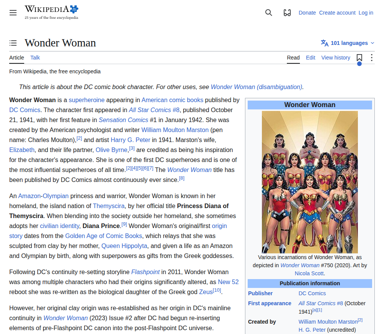

Captured and displayed the public article screenshot from https://en.wikipedia.org/wiki/Wonder_Woman.
BROWSER CHECK PASSED: a real Chromium screenshot was captured.


In [4]:
screenshots.clear()
browser_session = start_course_browser()
try:
    print(open_page(WONDER_WOMAN))
    print(capture_screenshot())
    assert screenshots and screenshots[-1].width > 0
    print("BROWSER CHECK PASSED: a real Chromium screenshot was captured.")
finally:
    browser_session.close()
    browser_session = None


## Gemini continuation — analyze the saved browser screenshot
The screenshot was captured by Chromium in the previous actual browser diagnostic. This call resumes visual analysis of that evidence without opening a browser again. It does not prove a full autonomous browser-agent execution.

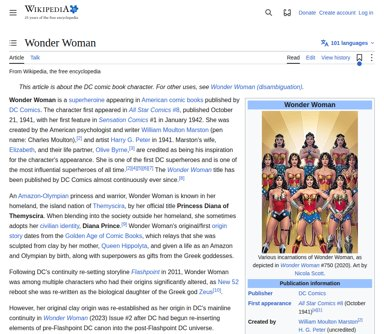

Based on the provided screenshot of https://en.wikipedia.org/wiki/Wonder_Woman, here is a description of the visible illustration:

### **Visual Description of the Illustration**
The sidebar image depicts an ensemble artwork featuring multiple fictional characters representing various incarnations of Wonder Woman. 

* **Composition:** The figures are arranged in a multi-row group against a golden, sunburst-like background. 
* **Costuming:** The figures wear variations of classic superhero armor and attire associated with Wonder Woman—predominantly red, blue, and gold color schemes, tiaras, star-patterned briefs or skirts, gauntlets (bracers), and tall boots. The designs vary in hairstyle, armor detailing, and tunic or cape styles across the different iterations.

---

### **Differentiation from Textual Context**
* **Visual Elements:** The description above is derived entirely from what is graphically rendered in the sidebar artwork—specifically the group arrangement, the poses, and the

In [1]:
import os
from openai import OpenAI
from IPython.display import display

def gemini_client():
    key = os.environ.get('AGENTS_GEMINI_KEY')
    if not key:
        from google.colab import userdata
        key = userdata.get('GEMINI_API_KEY')
    return OpenAI(api_key=key,base_url='https://generativelanguage.googleapis.com/v1beta/openai/',timeout=60,max_retries=0)

GEMINI_MODEL = 'gemini-3.5-flash-lite'

# Compressed copies of the actual images saved in the previous execution.
import base64
from io import BytesIO
from PIL import Image
saved_images = ['...']
for encoded in saved_images:
    display(Image.open(BytesIO(base64.b64decode(encoded))))
parts = [{'type':'text','text':'Alfred wants to compare a fictional guest costume with Wonder Woman. Inspect the saved Chromium screenshot of https://en.wikipedia.org/wiki/Wonder_Woman . Describe the visible fictional character illustration, differentiating what is visible from textual context. Cite the source URL. No guest photo was supplied; do not identify any real person or claim a guest identity. If the illustration is unclear, say so.'}]
parts += [{'type':'image_url','image_url':{'url':'data:image/jpeg;base64,'+encoded}} for encoded in saved_images]
client=gemini_client()
answer=client.chat.completions.create(model=GEMINI_MODEL,messages=[{'role':'user','content':parts}],max_tokens=1200)
response=answer.choices[0].message.content
if not response or not response.strip(): raise RuntimeError('Empty Gemini vision response')
print(response)
print('Gemini usage:',answer.usage)